# Example calculation of the number of BERs
Important to note that `compute_nb_reactions` uses intersection between two timestep sets to calculate the number of BERs.
As such, it works well when the output is frequent, but doesn't perform as well when logging bond information at low frequency.
This was calculated using high frequency output in the case of the publication.

For such a case as the frequency of output shown in this example, calculating the number of BERs using the thermo log would be more accurate.

In [3]:
from vast_pea.lammps_bonds import bond_dynamics
from vast_pea.computers import compute_nb_reactions

import matplotlib.pyplot as plt
import numpy as np

## Calculate number of BERs

In [ ]:
# start by reading/restoring a bond_dynamics object
bd = bond_dynamics(path="../../data/BER/save/",
                   pattern="afd_600K.bond_data.bonds.nc",
                   restore=True
                   )

bond_list = bd.get_bonds_setlist() # get list of sets of bonds. Each element of this list is the set of bonds for a specific timestep
nb_bers = compute_nb_reactions(bond_list) # get number of reactions for each timestep
nb_bers_cum = np.cumsum(nb_bers) # get cumulative sum of number of reactions
nb_bers_cum

	File list contains 1 files
	Bond Dynamics done!


array([   0,    0,    0,  250,  480,  712, 1045, 1357, 1694, 2042])

## add number of BERs at low temperature

In [10]:
bd_325 = bond_dynamics("../../data/BER/save/", "afd_325K.bond_data.bonds.nc", restore=True)

nb_bers_325 = np.cumsum(compute_nb_reactions(bd_325.get_bonds_setlist()))
nb_bers_325

	File list contains 1 files
	Bond Dynamics done!


array([  0,   0,   0,  42,  55,  70, 106, 150, 187, 207])

## Plot the number of BERs vs time

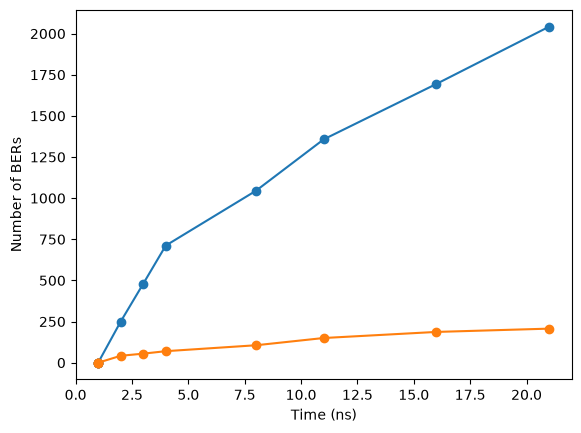

In [14]:
plt.plot(bd.timesteps/1e6, nb_bers, 'o-', label='600K')
plt.plot(bd.timesteps/1e6, nb_bers_325, 'o-', label='325K')
plt.xlabel("Time (ns)")
plt.ylabel("Number of BERs")
plt.show()